In [12]:
import pandas as pd

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
from sklearn.model_selection import train_test_split

In [15]:
df = pd.read_excel("/content/HousePrediction.xlsx")

In [16]:
df.head()

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0


### display first 100 rows

In [17]:
df.head(100)

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,60,RL,9765,Corner,1Fam,8,1993,1993,VinylSd,0.0,680.0,185000.0
96,96,20,RL,10264,Inside,1Fam,5,1999,1999,VinylSd,0.0,1588.0,214000.0
97,97,20,RL,10921,Inside,1Fam,5,1965,1965,HdBoard,0.0,960.0,94750.0
98,98,30,RL,10625,Corner,1Fam,5,1920,1950,Wd Sdng,0.0,458.0,83000.0


In [18]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotArea', 'LotConfig', 'BldgType',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'Exterior1st', 'BsmtFinSF2',
       'TotalBsmtSF', 'SalePrice'],
      dtype='object')

In [19]:
df.shape

(2919, 13)

In [20]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotArea', 'LotConfig', 'BldgType',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'Exterior1st', 'BsmtFinSF2',
       'TotalBsmtSF', 'SalePrice'],
      dtype='object')

In [21]:
df.dtypes

,0
Id,int64
MSSubClass,int64
MSZoning,object
LotArea,int64
LotConfig,object
BldgType,object
OverallCond,int64
YearBuilt,int64
YearRemodAdd,int64
Exterior1st,object


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Id            2919 non-null   int64  
 1   MSSubClass    2919 non-null   int64  
 2   MSZoning      2915 non-null   object 
 3   LotArea       2919 non-null   int64  
 4   LotConfig     2919 non-null   object 
 5   BldgType      2919 non-null   object 
 6   OverallCond   2919 non-null   int64  
 7   YearBuilt     2919 non-null   int64  
 8   YearRemodAdd  2919 non-null   int64  
 9   Exterior1st   2918 non-null   object 
 10  BsmtFinSF2    2918 non-null   float64
 11  TotalBsmtSF   2918 non-null   float64
 12  SalePrice     1460 non-null   float64
dtypes: float64(3), int64(6), object(4)
memory usage: 296.6+ KB


"Tell me how many missing values are present in every column."



In [23]:
df.isnull().sum()

,0
Id,0
MSSubClass,0
MSZoning,4
LotArea,0
LotConfig,0
BldgType,0
OverallCond,0
YearBuilt,0
YearRemodAdd,0
Exterior1st,1


only columns that have missing values

In [24]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

,0
MSZoning,4
Exterior1st,1
BsmtFinSF2,1
TotalBsmtSF,1
SalePrice,1459


Calculate percentage of missing data

In [25]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage[missing_percentage > 0].map(lambda x: f"{x:.2f}%")

,0
MSZoning,0.14%
Exterior1st,0.03%
BsmtFinSF2,0.03%
TotalBsmtSF,0.03%
SalePrice,49.98%


"Show me the rows where at least one value is missing."

In [26]:
df[df.isnull().any(axis=1)]

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
1460,1460,20,RH,11622,Inside,1Fam,6,1961,1961,VinylSd,144.0,882.0,NaN
1461,1461,20,RL,14267,Corner,1Fam,6,1958,1958,Wd Sdng,0.0,1329.0,NaN
1462,1462,60,RL,13830,Inside,1Fam,5,1997,1998,VinylSd,0.0,928.0,NaN
1463,1463,60,RL,9978,Inside,1Fam,6,1998,1998,VinylSd,0.0,926.0,NaN
1464,1464,120,RL,5005,Inside,TwnhsE,5,1992,1992,HdBoard,0.0,1280.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2914,2914,160,RM,1936,Inside,Twnhs,7,1970,1970,CemntBd,0.0,546.0,NaN
2915,2915,160,RM,1894,Inside,TwnhsE,5,1970,1970,CemntBd,0.0,546.0,NaN
2916,2916,20,RL,20000,Inside,1Fam,7,1960,1996,VinylSd,0.0,1224.0,NaN
2917,2917,85,RL,10441,Inside,1Fam,5,1992,1992,HdBoard,0.0,912.0,NaN


inspect the missing columns individually

In [27]:
df[df["MSZoning"].isnull()]

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
1915,1915,30,NaN,21780,Inside,1Fam,4,1910,1950,Wd Sdng,0.0,0.0,NaN
2216,2216,20,NaN,14584,Inside,1Fam,5,1952,1952,AsbShng,0.0,0.0,NaN
2250,2250,70,NaN,56600,Inside,1Fam,1,1900,1950,Wd Sdng,0.0,686.0,NaN
2904,2904,20,NaN,31250,Inside,1Fam,3,1951,1951,CBlock,0.0,0.0,NaN


In [28]:
df[df["Exterior1st"].isnull()]

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
2151,2151,30,RL,19550,Inside,1Fam,7,1940,2007,NaN,0.0,1580.0,NaN


In [29]:
df[df["BsmtFinSF2"].isnull()]

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
2120,2120,20,RM,5940,FR3,1Fam,7,1946,1950,MetalSd,NaN,NaN,NaN


In [30]:
df[df["TotalBsmtSF"].isnull()]

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
2120,2120,20,RM,5940,FR3,1Fam,7,1946,1950,MetalSd,NaN,NaN,NaN


In [31]:
df[df["SalePrice"].isnull()].head()

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
1460,1460,20,RH,11622,Inside,1Fam,6,1961,1961,VinylSd,144.0,882.0,NaN
1461,1461,20,RL,14267,Corner,1Fam,6,1958,1958,Wd Sdng,0.0,1329.0,NaN
1462,1462,60,RL,13830,Inside,1Fam,5,1997,1998,VinylSd,0.0,928.0,NaN
1463,1463,60,RL,9978,Inside,1Fam,6,1998,1998,VinylSd,0.0,926.0,NaN
1464,1464,120,RL,5005,Inside,TwnhsE,5,1992,1992,HdBoard,0.0,1280.0,NaN


most common values of the categorical columns

In [32]:
df["MSZoning"].value_counts()

,count
MSZoning,
RL,2265
RM,460
FV,139
RH,26
C (all),25


In [33]:
df["Exterior1st"].value_counts()

,count
Exterior1st,
VinylSd,1025
MetalSd,450
HdBoard,442
Wd Sdng,411
Plywood,221
CemntBd,126
BrkFace,87
WdShing,56
AsbShng,44


"Show me the house where BsmtFinSF2 is missing."

In [34]:
df[df["BsmtFinSF2"].isnull()]

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
2120,2120,20,RM,5940,FR3,1Fam,7,1946,1950,MetalSd,NaN,NaN,NaN


"Show me the house where TotalBsmtSF is missing."

In [35]:
df[df["TotalBsmtSF"].isnull()]

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
2120,2120,20,RM,5940,FR3,1Fam,7,1946,1950,MetalSd,NaN,NaN,NaN


In [36]:
df.loc[df["Id"] == 2120, [
    "Id",
    "MSZoning",
    "LotArea",
    "BldgType",
    "OverallCond",
    "YearBuilt",
    "YearRemodAdd",
    "Exterior1st",
    "BsmtFinSF2",
    "TotalBsmtSF",
    "SalePrice"
]]

,Id,MSZoning,LotArea,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
2120,2120,RM,5940,1Fam,7,1946,1950,MetalSd,NaN,NaN,NaN


In [37]:
df[["BsmtFinSF2", "TotalBsmtSF"]].describe()

,BsmtFinSF2,TotalBsmtSF
count,2918.000000,2918.000000
mean,49.582248,1051.777587
std,169.205611,440.766258
min,0.000000,0.000000
25%,0.000000,793.000000
50%,0.000000,989.500000
75%,0.000000,1302.000000
max,1526.000000,6110.000000


In [38]:
df[df["TotalBsmtSF"] == 0][["Id", "BsmtFinSF2", "TotalBsmtSF"]].head(10)

,Id,BsmtFinSF2,TotalBsmtSF
17,17,0.0,0.0
39,39,0.0,0.0
90,90,0.0,0.0
102,102,0.0,0.0
156,156,0.0,0.0
182,182,0.0,0.0
259,259,0.0,0.0
342,342,0.0,0.0
362,362,0.0,0.0
371,371,0.0,0.0


In [39]:
df["BsmtFinSF2"] = df["BsmtFinSF2"].fillna(0)
df["TotalBsmtSF"] = df["TotalBsmtSF"].fillna(0)

In [40]:

df[["BsmtFinSF2", "TotalBsmtSF"]].isnull().sum()

,0
BsmtFinSF2,0
TotalBsmtSF,0


In [41]:
df["MSZoning"].isnull().sum()

np.int64(4)

In [42]:
df["MSZoning"].value_counts()

,count
MSZoning,
RL,2265
RM,460
FV,139
RH,26
C (all),25


Fill the 4 missing MSZoning values





In [43]:
df["MSZoning"] = df["MSZoning"].fillna("RL")

In [44]:
df["MSZoning"].isnull().sum()

np.int64(0)

In [45]:
df["Exterior1st"].value_counts()

,count
Exterior1st,
VinylSd,1025
MetalSd,450
HdBoard,442
Wd Sdng,411
Plywood,221
CemntBd,126
BrkFace,87
WdShing,56
AsbShng,44


In [46]:
df["Exterior1st"] = df["Exterior1st"].fillna("VinylSd")

In [47]:
df["Exterior1st"].isnull().sum()

np.int64(0)

backup of the original dataset

In [48]:
df_original = pd.read_excel("/content/HousePrediction.xlsx")

## **Calculate Mean SalePrice for Missing/Present Information**





This analysis compares the average SalePrice of houses where information is present vs missing for features containing missing values.

---



**1 - Mean SalePrice Based on MSZoning Information**

We compare the average SalePrice of houses where MSZoning information is present and where it is missing.

In [49]:
df_original["MSZoning_missing"] = df_original["MSZoning"].isnull()

In [50]:
df_original.groupby("MSZoning_missing")["SalePrice"].mean()

,SalePrice
MSZoning_missing,
False,180921.19589
True,NaN


The mean SalePrice for records where MSZoning information was present was approximately 180,921.20. The mean SalePrice for records where MSZoning was missing could not be calculated because those records also had missing SalePrice values.

**2 — Mean SalePrice Based on Exterior1st Information**

In [51]:
df_original["Exterior1st_missing"] = df_original["Exterior1st"].isnull()

In [52]:
df_original.groupby("Exterior1st_missing")["SalePrice"].mean()

,SalePrice
Exterior1st_missing,
False,180921.19589
True,NaN


The mean SalePrice for records where Exterior1st information was present was approximately 180,921.20. The mean SalePrice for the record where Exterior1st was missing could not be calculated because its SalePrice was also missing.

**3 — Mean SalePrice Based on BsmtFinSF2 Information**

In [53]:
df_original["BsmtFinSF2_missing"] = df_original["BsmtFinSF2"].isnull()

In [54]:
df_original.groupby("BsmtFinSF2_missing")["SalePrice"].mean()

,SalePrice
BsmtFinSF2_missing,
False,180921.19589
True,NaN


The mean SalePrice for records where BsmtFinSF2 information was present was approximately 180,921.20. The mean SalePrice for the record where BsmtFinSF2 was missing could not be calculated because its SalePrice was also missing.

**4 — Mean SalePrice Based on TotalBsmtSF Information**

In [55]:
df_original["TotalBsmtSF_missing"] = df_original["TotalBsmtSF"].isnull()

In [56]:
df_original.groupby("TotalBsmtSF_missing")["SalePrice"].mean()

,SalePrice
TotalBsmtSF_missing,
False,180921.19589
True,NaN


## **Count the Number of Numerical Features**

Identifies and counts the features that contain numerical data in the dataset.

In [57]:
numerical_features = df.select_dtypes(include=["int64", "float64"]).columns

len(numerical_features)

9

In [58]:
numerical_features

Index(['Id', 'MSSubClass', 'LotArea', 'OverallCond', 'YearBuilt',
       'YearRemodAdd', 'BsmtFinSF2', 'TotalBsmtSF', 'SalePrice'],
      dtype='object')

"The dataset contains 9 numerical features. These features contain numerical data and can be used for numerical analysis and statistical calculations"

## **First Five Rows of Numerical Values**

In [59]:
df[numerical_features].head()

,Id,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,8450,5,2003,2003,0.0,856.0,208500.0
1,1,20,9600,8,1976,1976,0.0,1262.0,181500.0
2,2,60,11250,5,2001,2002,0.0,920.0,223500.0
3,3,70,9550,5,1915,1970,0.0,756.0,140000.0
4,4,60,14260,5,2000,2000,0.0,1145.0,250000.0


## **Histogram Analysis for Continuous Variables**

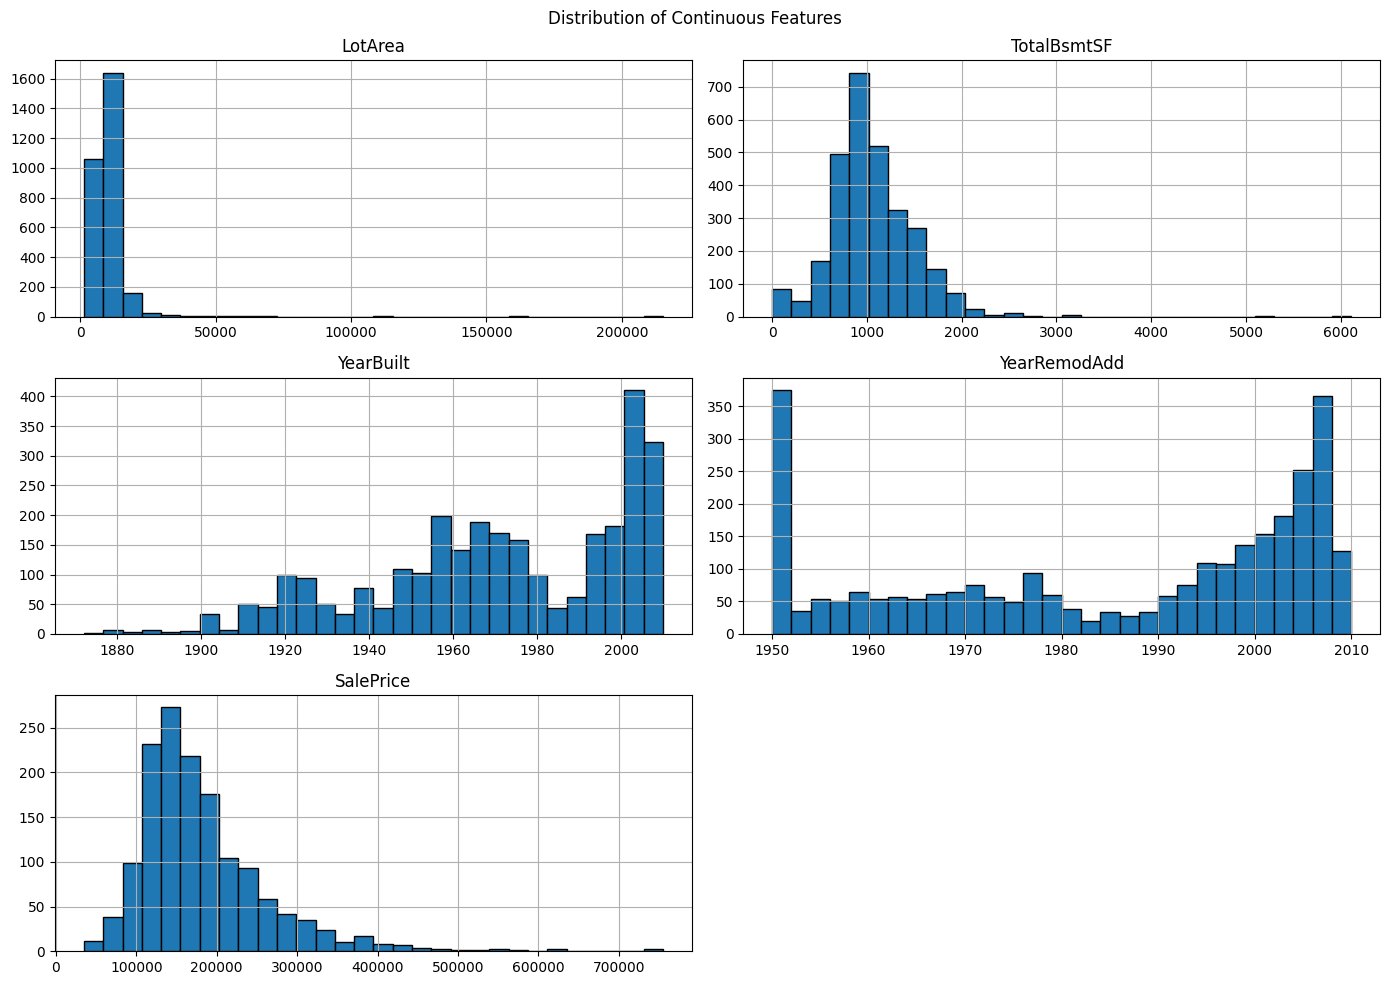

In [60]:
import matplotlib.pyplot as plt

continuous_features = [
    "LotArea",
    "TotalBsmtSF",
    "YearBuilt",
    "YearRemodAdd",
    "SalePrice"
]

df[continuous_features].hist(
    bins=30,
    figsize=(14, 10),
    edgecolor="black"
)

plt.suptitle("Distribution of Continuous Features")
plt.tight_layout()
plt.show()

"Histograms help identify the distribution and spread of numerical features. They can reveal skewness and unusual values, which may need further investigation before model training."

## **Logarithmic Transformation**

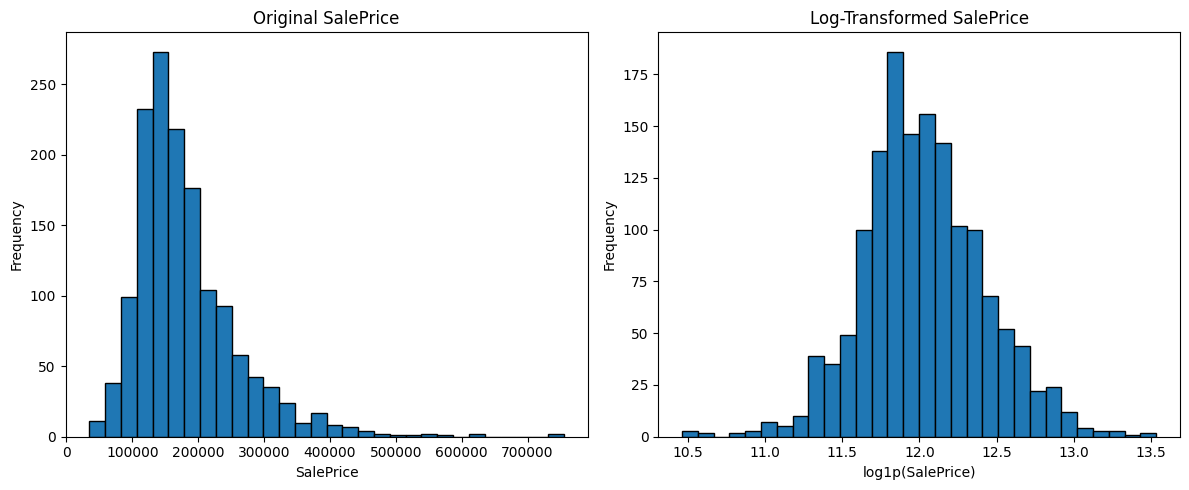

In [61]:
import numpy as np
import matplotlib.pyplot as plt

# Use only available SalePrice values
saleprice = df["SalePrice"].dropna()

# Apply logarithmic transformation
log_saleprice = np.log1p(saleprice)

# Compare original and transformed distributions
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(saleprice, bins=30, edgecolor="black")
plt.title("Original SalePrice")
plt.xlabel("SalePrice")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(log_saleprice, bins=30, edgecolor="black")
plt.title("Log-Transformed SalePrice")
plt.xlabel("log1p(SalePrice)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## **Analyze Year Features vs SalePrice**

---



This analysis examines the relationship between year-related features and SalePrice using visualizations.

**YearBuilt vs SalePrice**

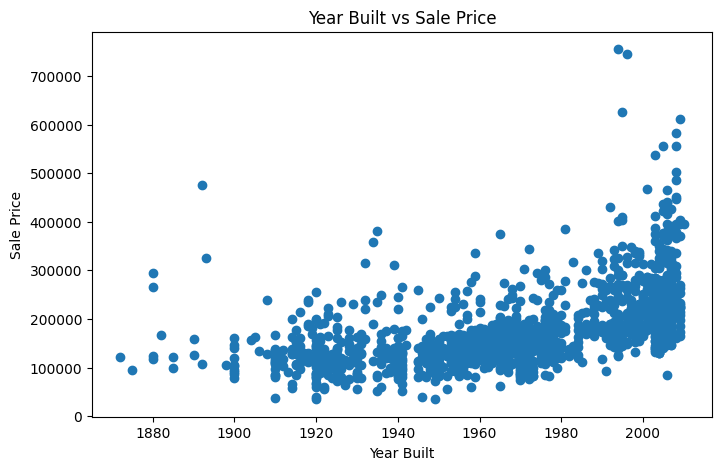

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.scatter(df["YearBuilt"], df["SalePrice"])
plt.xlabel("Year Built")
plt.ylabel("Sale Price")
plt.title("Year Built vs Sale Price")
plt.show()

"The scatter plot shows a generally positive relationship between YearBuilt and SalePrice. Newer houses tend to have higher SalePrice values. However, the wide distribution of points indicates that YearBuilt alone does not determine house prices. Other features also influence SalePrice."

**YearRemodAdd vs SalePrice**

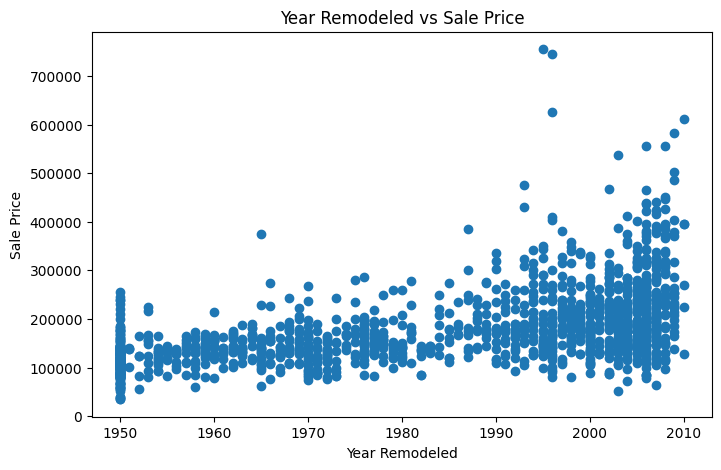

In [63]:
plt.figure(figsize=(8, 5))
plt.scatter(df["YearRemodAdd"], df["SalePrice"])
plt.xlabel("Year Remodeled")
plt.ylabel("Sale Price")
plt.title("Year Remodeled vs Sale Price")
plt.show()

"The scatter plot shows a generally positive relationship between YearRemodAdd and SalePrice. Houses remodeled in more recent years tend to have higher selling prices, although there is considerable variation. This suggests that the remodeling year may be associated with house prices, but other features also influence SalePrice."

## **Analyze Discrete Variables vs SalePrice**

1 — Identify Discrete Numerical Features

In [64]:
discrete_features = [
    col for col in numerical_features
    if df[col].nunique() < 20 and col != "SalePrice"
]

discrete_features

['MSSubClass', 'OverallCond']

2 — Average SalePrice by MSSubClass

In [65]:
df.groupby("MSSubClass")["SalePrice"].mean().round(2)

,SalePrice
MSSubClass,
20,185224.81
30,95829.72
40,156125.00
45,108591.67
50,143302.97
60,239948.50
70,166772.42
75,192437.50
80,169736.55


3 — Visualize Average SalePrice by MSSubClass


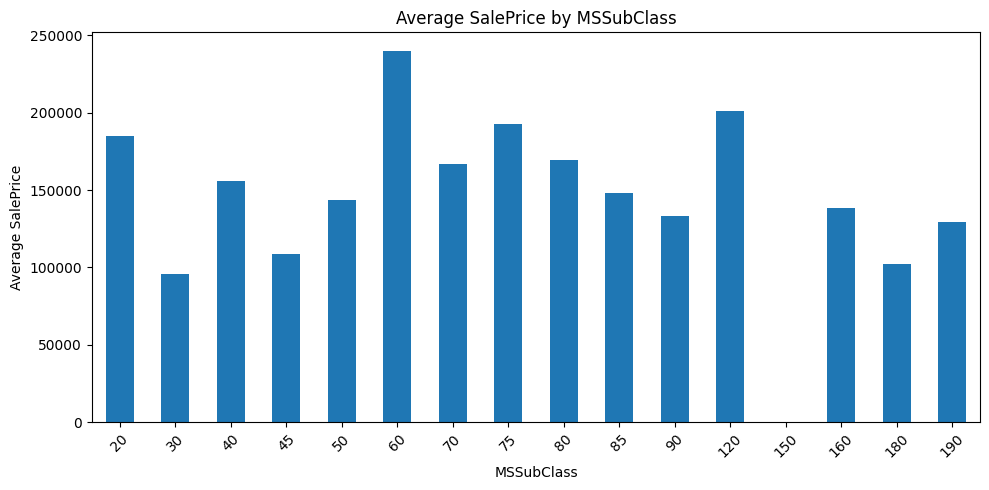

In [66]:
import matplotlib.pyplot as plt

df.groupby("MSSubClass")["SalePrice"].mean().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("MSSubClass")
plt.ylabel("Average SalePrice")
plt.title("Average SalePrice by MSSubClass")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

4— Average SalePrice by OverallCond

In [67]:
df.groupby("OverallCond")["SalePrice"].mean().round(2)

,SalePrice
OverallCond,
1,61000.00
2,141986.40
3,101929.40
4,120438.44
5,203146.91
6,153961.59
7,158145.49
8,155651.74
9,216004.55


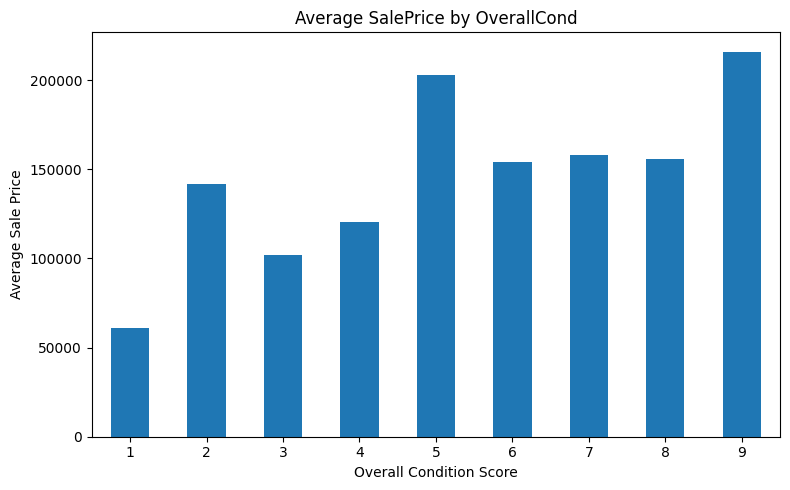

In [68]:

import matplotlib.pyplot as plt

df.groupby("OverallCond")["SalePrice"].mean().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Overall Condition Score")
plt.ylabel("Average Sale Price")
plt.title("Average SalePrice by OverallCond")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


" Houses with a condition score of 9 have the highest average selling price, while houses with a score of 1 have the lowest."

## **Categorical Feature Analysis**

---



In [69]:
categorical_features = df.select_dtypes(include=["object"]).columns

categorical_features

Index(['MSZoning', 'LotConfig', 'BldgType', 'Exterior1st'], dtype='object')

1— Count Unique Categories

In [70]:

for col in categorical_features:
    print(col, ":", df[col].nunique(), "unique categories")


MSZoning : 5 unique categories
LotConfig : 5 unique categories
BldgType : 5 unique categories
Exterior1st : 15 unique categories


2— Display Categories in Each Feature

In [71]:
for col in categorical_features:
    print("\n", col)
    print(df[col].unique())



 MSZoning
['RL' 'RM' 'C (all)' 'FV' 'RH']

 LotConfig
['Inside' 'FR2' 'Corner' 'CulDSac' 'FR3']

 BldgType
['1Fam' '2fmCon' 'Duplex' 'TwnhsE' 'Twnhs']

 Exterior1st
['VinylSd' 'MetalSd' 'Wd Sdng' 'HdBoard' 'BrkFace' 'WdShing' 'CemntBd'
 'Plywood' 'AsbShng' 'Stucco' 'BrkComm' 'AsphShn' 'Stone' 'ImStucc'
 'CBlock']


3— Visualize Categorical Features

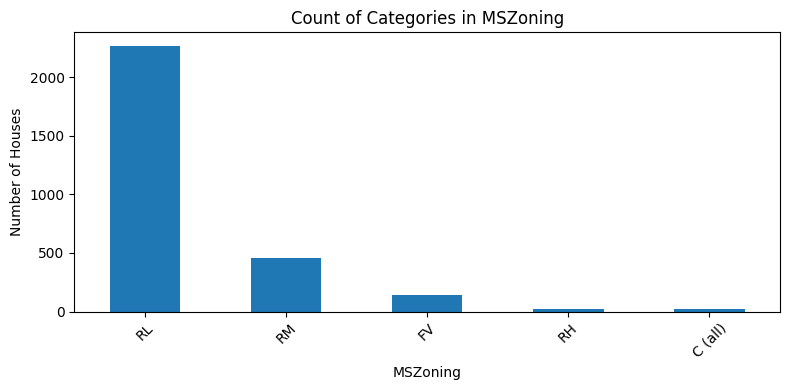

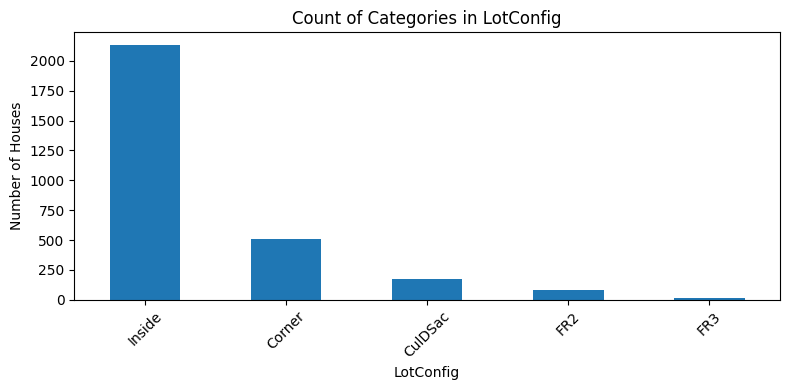

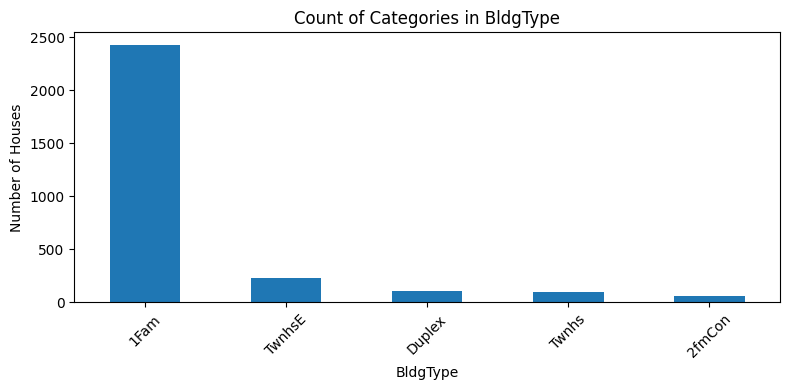

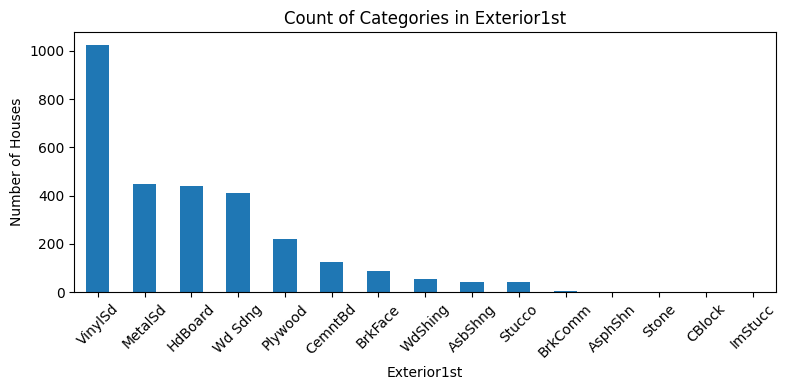

In [72]:
import matplotlib.pyplot as plt

for col in categorical_features:
    df[col].value_counts().plot(kind="bar", figsize=(8, 4))
    plt.title("Count of Categories in " + col)
    plt.xlabel(col)
    plt.ylabel("Number of Houses")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


## **Analyze Categorical Features vs SalePrice**

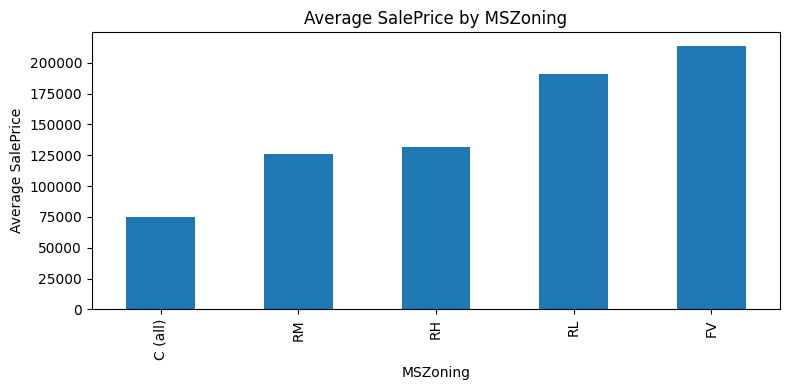

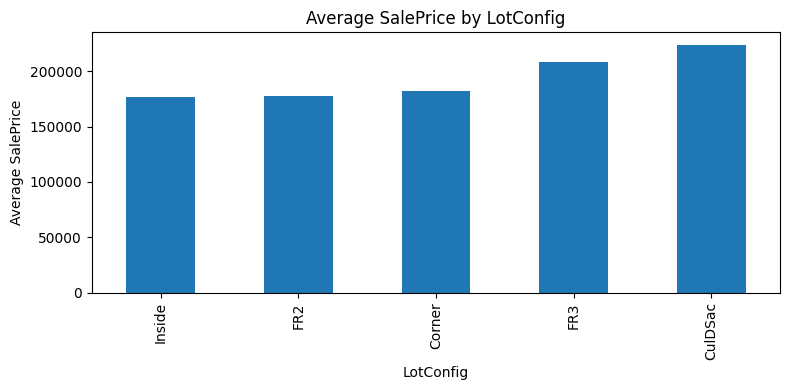

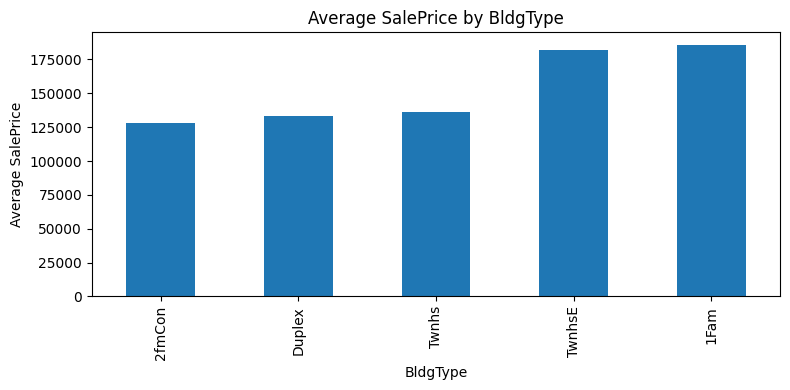

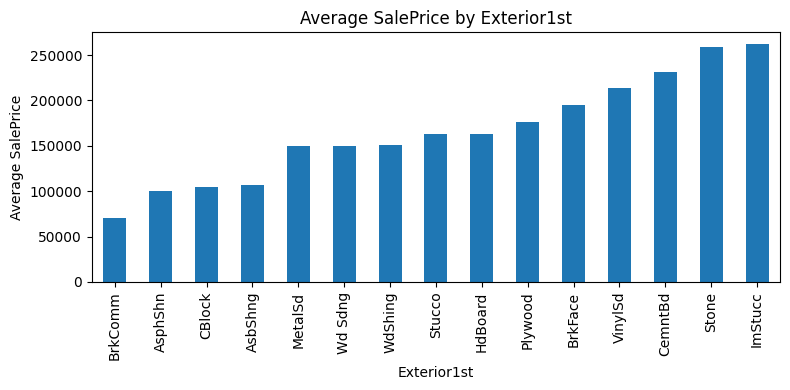

In [94]:
categorical_features = [
    "MSZoning",
    "LotConfig",
    "BldgType",
    "Exterior1st"
]

for col in categorical_features:
    df.groupby(col)["SalePrice"].mean().sort_values().plot(
        kind="bar", figsize=(8, 4), title=f"Average SalePrice by {col}"
    )
    plt.ylabel("Average SalePrice")
    plt.tight_layout()
    plt.show()

## **Missing Value Analysis in Categorical Features**

In [73]:
df[categorical_features].isnull().sum()

,0
MSZoning,0
LotConfig,0
BldgType,0
Exterior1st,0


"The missing-value analysis shows that MSZoning, LotConfig, BldgType, and Exterior1st contain zero missing values."



## **Correlation Analysis**

1 — Calculate Correlation Matrix



In [74]:
correlation_matrix = df[numerical_features].corr()

correlation_matrix.round(2)


,Id,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,SalePrice
Id,1.00,0.01,-0.04,-0.00,-0.02,-0.05,0.02,-0.03,-0.02
MSSubClass,0.01,1.00,-0.20,-0.07,0.03,0.04,-0.07,-0.22,-0.08
LotArea,-0.04,-0.20,1.00,-0.04,0.02,0.02,0.08,0.25,0.26
OverallCond,-0.00,-0.07,-0.04,1.00,-0.37,0.05,0.04,-0.17,-0.08
YearBuilt,-0.02,0.03,0.02,-0.37,1.00,0.61,-0.03,0.41,0.52
YearRemodAdd,-0.05,0.04,0.02,0.05,0.61,1.00,-0.06,0.30,0.51
BsmtFinSF2,0.02,-0.07,0.08,0.04,-0.03,-0.06,1.00,0.09,-0.01
TotalBsmtSF,-0.03,-0.22,0.25,-0.17,0.41,0.30,0.09,1.00,0.61
SalePrice,-0.02,-0.08,0.26,-0.08,0.52,0.51,-0.01,0.61,1.00


2 — Correlation Heatmap

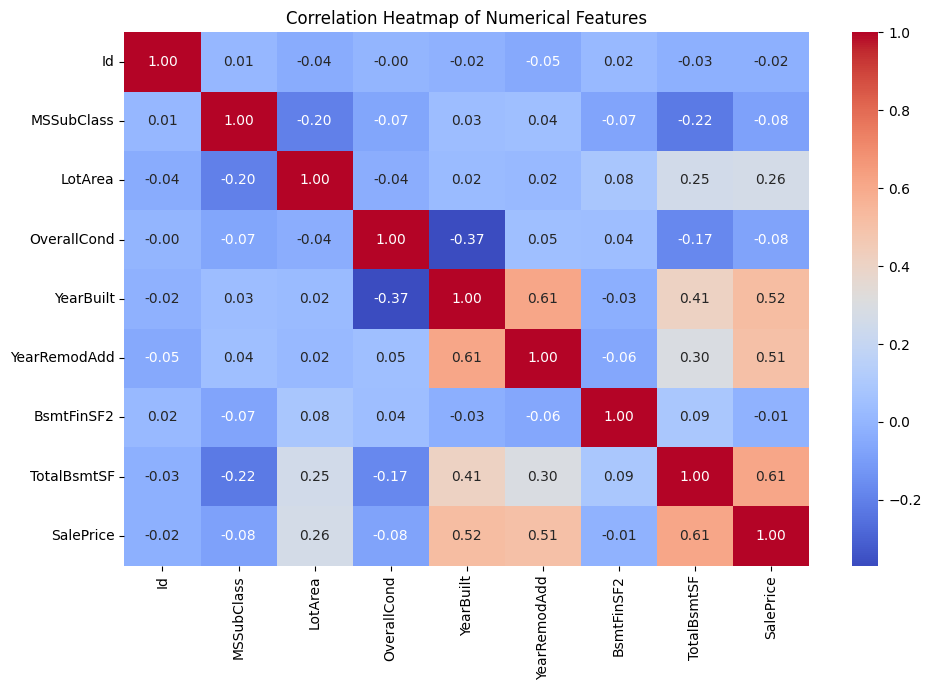

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


3 — Features Correlated with SalePrice

In [76]:
saleprice_correlation = correlation_matrix["SalePrice"].drop("SalePrice")

saleprice_correlation.sort_values(ascending=False).round(2)


,SalePrice
TotalBsmtSF,0.61
YearBuilt,0.52
YearRemodAdd,0.51
LotArea,0.26
BsmtFinSF2,-0.01
Id,-0.02
OverallCond,-0.08
MSSubClass,-0.08


"The correlation analysis shows that TotalBsmtSF has the strongest positive correlation with SalePrice among the numerical features displayed, at 0.61. YearBuilt (0.52) and YearRemodAdd (0.51) also show positive relationships with sale price. BsmtFinSF2, Id, OverallCond, and MSSubClass have correlations close to zero."

## **Data Preparation for Machine Learning**

1 — Separate Available and Missing Sale Prices

In [77]:
print("Total rows:", len(df))
print("Available SalePrice:", df["SalePrice"].notna().sum())
print("Missing SalePrice:", df["SalePrice"].isna().sum())

Total rows: 2919
Available SalePrice: 1460
Missing SalePrice: 1459


2 — Create Dataset with Known Sale Prices

In [78]:
train_df = df[df["SalePrice"].notna()].copy()

print("Training dataset shape:", train_df.shape)
print("Missing SalePrice in training data:", train_df["SalePrice"].isna().sum())

Training dataset shape: (1460, 13)
Missing SalePrice in training data: 0


3 — Missing Value Analysis in Training Data

In [79]:
missing_values = train_df.isnull().sum()

missing_values[missing_values > 0].sort_values(ascending=False)

,0


4 — Percentage of Missing Values

In [80]:
missing_percent = (train_df.isnull().sum() / len(train_df)) * 100

missing_percent[missing_percent > 0].sort_values(ascending=False).round(2)

,0


"The missing-value analysis confirms that the training dataset contains no missing values in any column. The percentage of missing values is therefore 0% for all columns. No missing-value treatment is required for the current training dataset."

5 — Separate Features (X) and Target (y)

In [81]:
X = train_df.drop("SalePrice", axis=1)
y = train_df["SalePrice"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (1460, 12)
Target (y) shape: (1460,)


6 — Split Data into Training and Testing Sets

In [82]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1168, 12)
X_test: (292, 12)
y_train: (1168,)
y_test: (292,)


7 — Identify Feature Data Types

In [83]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features_model = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features_model)
print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features_model))

Numerical features: ['Id', 'MSSubClass', 'LotArea', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'BsmtFinSF2', 'TotalBsmtSF']

Categorical features: ['MSZoning', 'LotConfig', 'BldgType', 'Exterior1st']

Number of numerical features: 8
Number of categorical features: 4


8 — Encode Categorical Features and Prepare Numerical Features

In [84]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Treat MSSubClass as categorical
categorical_cols = categorical_features_model + ["MSSubClass"]

# Remaining numerical columns
numeric_cols = [col for col in numeric_features if col != "MSSubClass"]

# Prepare numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Prepare categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)
print("Preprocessor created successfully.")

Numerical columns: ['Id', 'LotArea', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'BsmtFinSF2', 'TotalBsmtSF']
Categorical columns: ['MSZoning', 'LotConfig', 'BldgType', 'Exterior1st', 'MSSubClass']
Preprocessor created successfully.


9 — Train Random Forest Regression Model

In [85]:
from sklearn.ensemble import RandomForestRegressor

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


## **Model Evaluation**

1 — Predict Sale Prices

In [86]:
y_pred = model.predict(X_test)

print("First 10 actual prices:")
print(y_test.head(10).values)

print("\nFirst 10 predicted prices:")
print(y_pred[:10])

First 10 actual prices:
[154500. 325000. 115000. 159000. 315500.  75500. 311500. 146000.  84500.
 135500.]

First 10 predicted prices:
[149838.375 299129.75  116249.5   131738.125 272927.075  94242.205
 240242.    138534.175  93830.705 173812.735]


2 — Evaluate Model Performance

In [87]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R² Score:", round(r2, 4))

Mean Absolute Error (MAE): 22945.36
Root Mean Squared Error (RMSE): 37063.48
R² Score: 0.8209


"The Random Forest Regressor achieved an MAE of $22,945.36, an RMSE of $37,063.48, and an R² score of 0.8209 on the test set. These results indicate that the model captures a substantial proportion of the variation in house sale prices, although prediction errors remain"

## **Actual vs Predicted House Prices**

1 — Actual vs Predicted Price Scatter Plot

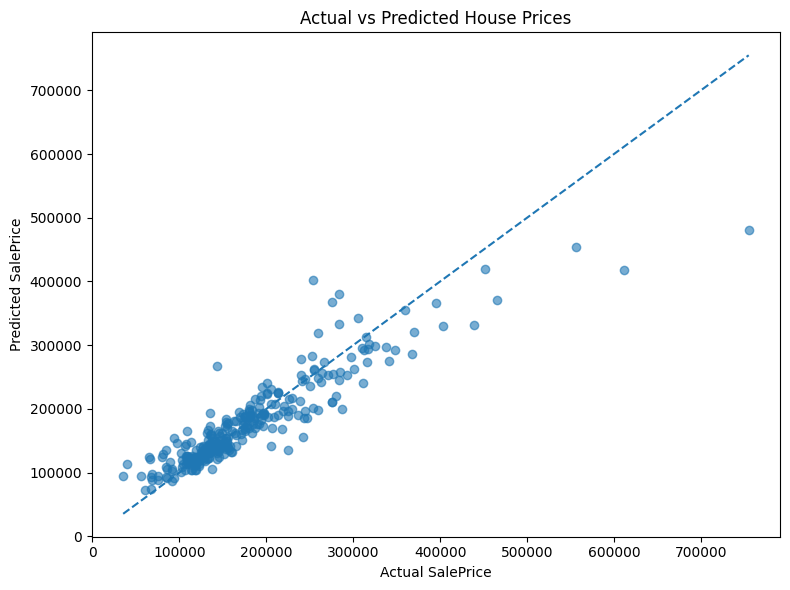

In [88]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Actual vs Predicted House Prices")

# Reference line for perfect predictions
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.tight_layout()
plt.show()

"The scatter plot shows that predicted house prices generally follow the trend of actual sale prices. However, some predictions deviate from the perfect-prediction line, particularly for certain high-priced houses."

## **Feature Importance Analysis**

1 — Calculate Feature Importance

In [89]:
import pandas as pd
import matplotlib.pyplot as plt

# Get the fitted preprocessing step
fitted_preprocessor = model.named_steps["preprocessor"]

# Get names of the transformed features
feature_names = fitted_preprocessor.get_feature_names_out()

# Get feature importance scores from the trained Random Forest
importance_scores = model.named_steps["regressor"].feature_importances_

# Create and sort the importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
}).sort_values(by="Importance", ascending=False)

feature_importance.head(10)

,Feature,Importance
6,num__TotalBsmtSF,0.319975
3,num__YearBuilt,0.310707
1,num__LotArea,0.125652
42,cat__MSSubClass_60,0.074709
4,num__YearRemodAdd,0.041767
0,num__Id,0.027566
2,num__OverallCond,0.025767
35,cat__Exterior1st_Wd Sdng,0.010768
25,cat__Exterior1st_BrkFace,0.008644
38,cat__MSSubClass_30,0.005332


2 — Visualize Top 10 Important Features

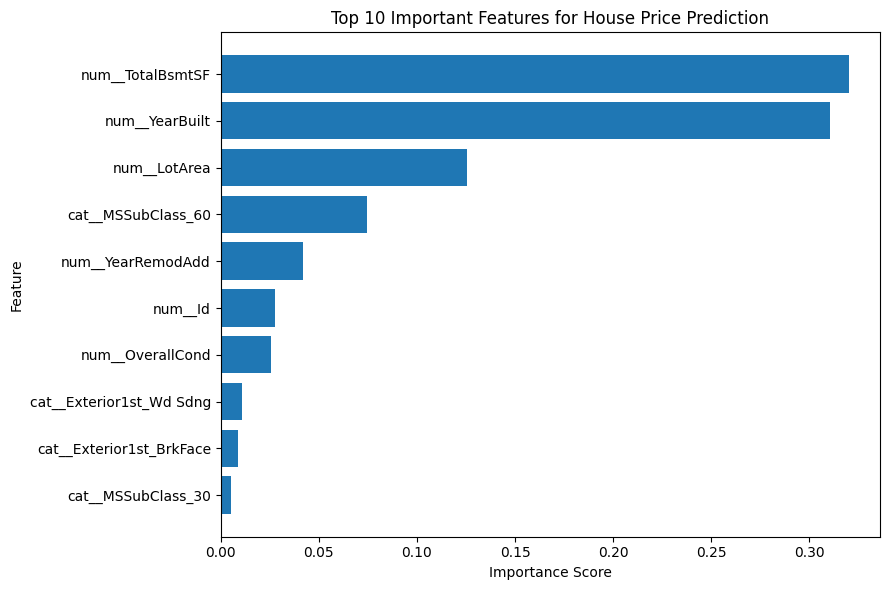

In [90]:
top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Important Features for House Price Prediction")
plt.tight_layout()
plt.show()

"The feature importance graph shows that TotalBsmtSF and YearBuilt are the two most important features in the trained Random Forest model. LotArea is the third most important feature."

## **Model Improvement and Comparison**

In [91]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

improved_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

improved_model.fit(X_train, y_train)

improved_pred = improved_model.predict(X_test)

improved_mae = mean_absolute_error(y_test, improved_pred)
improved_rmse = np.sqrt(mean_squared_error(y_test, improved_pred))
improved_r2 = r2_score(y_test, improved_pred)

print("Improved Model MAE:", round(improved_mae, 2))
print("Improved Model RMSE:", round(improved_rmse, 2))
print("Improved Model R²:", round(improved_r2, 4))

Improved Model MAE: 22986.02
Improved Model RMSE: 36580.73
Improved Model R²: 0.8255


## **Model Performance Comparison**

   Model        MAE       RMSE     R2
Original 22945.3556 37063.4755 0.8209
Improved 22986.0215 36580.7295 0.8255


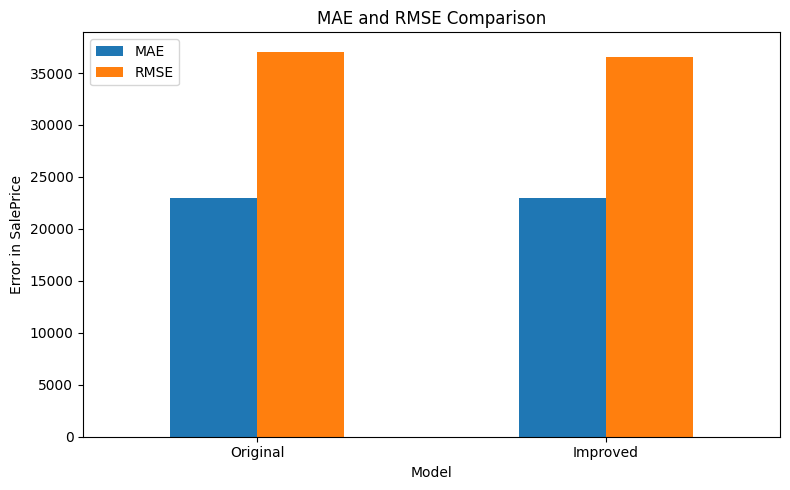

In [92]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": ["Original", "Improved"],
    "MAE": [mae, improved_mae],
    "RMSE": [rmse, improved_rmse],
    "R2": [r2, improved_r2]
})

print(comparison.round(4).to_string(index=False))

comparison.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("MAE and RMSE Comparison")
plt.ylabel("Error in SalePrice")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## **Impact of Zoning and Lot Configuration on SalePrice**

Average SalePrice by MSZoning:
MSZoning
C (all)     74528.00
RM         126316.83
RH         131558.38
RL         191004.99
FV         214014.06
Name: SalePrice, dtype: float64


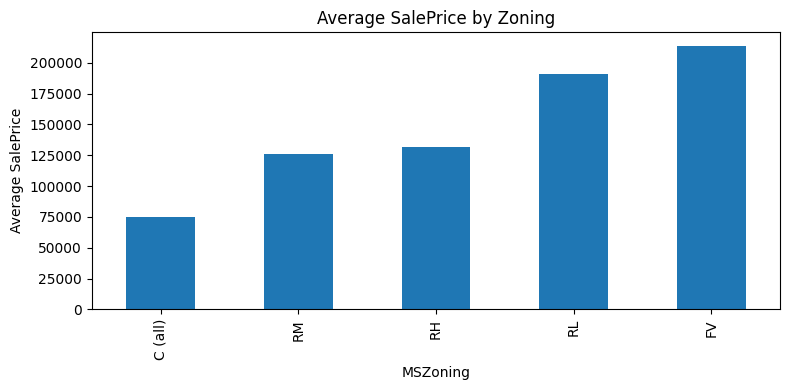

Average SalePrice by LotConfig:
LotConfig
Inside     176938.05
FR2        177934.57
Corner     181623.43
FR3        208475.00
CulDSac    223854.62
Name: SalePrice, dtype: float64


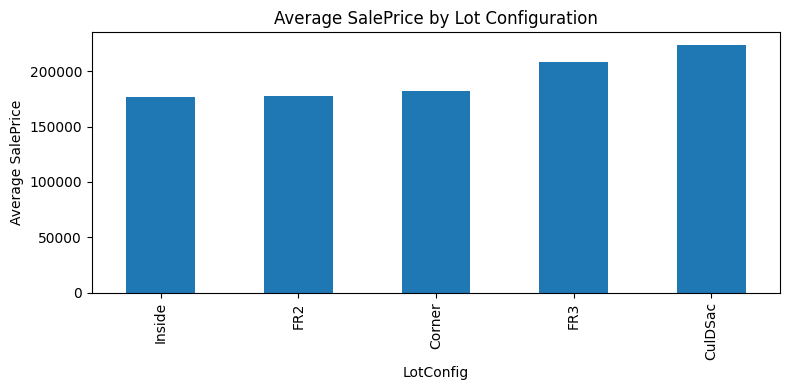

In [95]:
import matplotlib.pyplot as plt

# Average SalePrice by zoning
zoning_price = df.groupby("MSZoning")["SalePrice"].mean().sort_values()

print("Average SalePrice by MSZoning:")
print(zoning_price.round(2))

zoning_price.plot(kind="bar", figsize=(8, 4))
plt.title("Average SalePrice by Zoning")
plt.xlabel("MSZoning")
plt.ylabel("Average SalePrice")
plt.tight_layout()
plt.show()

# Average SalePrice by lot configuration
lot_price = df.groupby("LotConfig")["SalePrice"].mean().sort_values()

print("Average SalePrice by LotConfig:")
print(lot_price.round(2))

lot_price.plot(kind="bar", figsize=(8, 4))
plt.title("Average SalePrice by Lot Configuration")
plt.xlabel("LotConfig")
plt.ylabel("Average SalePrice")
plt.tight_layout()
plt.show()

"The average sale price varies across zoning categories and lot configurations."

## **Impact of Overall Condition on SalePrice**

Average SalePrice by Overall Condition:
OverallCond
1     61000.00
2    141986.40
3    101929.40
4    120438.44
5    203146.91
6    153961.59
7    158145.49
8    155651.74
9    216004.55
Name: SalePrice, dtype: float64


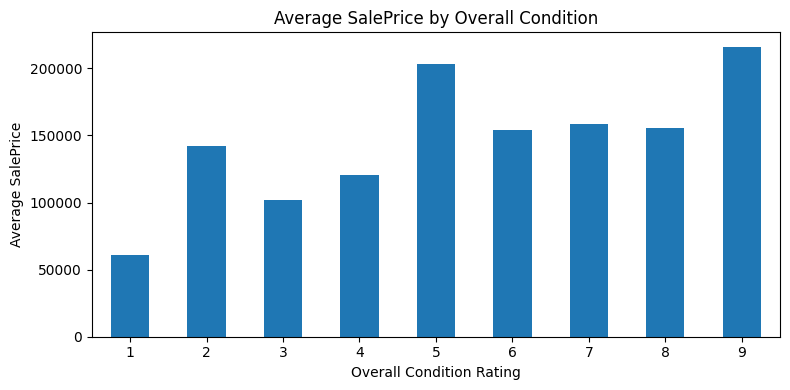

In [96]:
condition_price = (
    df.groupby("OverallCond")["SalePrice"]
    .mean()
    .sort_index()
)

print("Average SalePrice by Overall Condition:")
print(condition_price.round(2))

condition_price.plot(kind="bar", figsize=(8, 4))

plt.title("Average SalePrice by Overall Condition")
plt.xlabel("Overall Condition Rating")
plt.ylabel("Average SalePrice")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

"Average SalePrice differs across overall-condition ratings."

## **Impact of Basement Presence on SalePrice**

Average SalePrice by Basement Presence:
HasBasement
With Basement       182878.28
Without Basement    105652.89
Name: SalePrice, dtype: float64


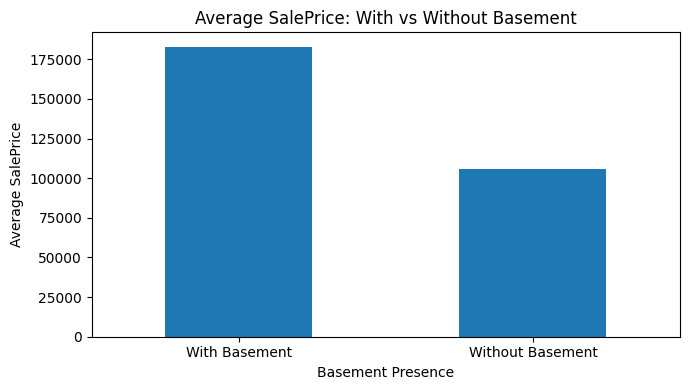

In [97]:
# Create a basement-presence category
df["HasBasement"] = df["TotalBsmtSF"].apply(
    lambda area: "With Basement" if area > 0 else "Without Basement"
)

# Compare average sale prices
basement_price = df.groupby("HasBasement")["SalePrice"].mean()

print("Average SalePrice by Basement Presence:")
print(basement_price.round(2))

basement_price.plot(kind="bar", figsize=(7, 4))

plt.title("Average SalePrice: With vs Without Basement")
plt.xlabel("Basement Presence")
plt.ylabel("Average SalePrice")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## **Predict the Price of a New House**

1 — Select a Sample House

In [98]:
# Select one house from the test dataset
sample_house = X_test.iloc[[0]]

# Predict its price using the improved model
predicted_price = improved_model.predict(sample_house)[0]

# Get the actual price for comparison
actual_price = y_test.iloc[0]

print("Predicted House Price:", round(predicted_price, 2))
print("Actual House Price:", round(actual_price, 2))
print("Absolute Prediction Error:", round(abs(actual_price - predicted_price), 2))

Predicted House Price: 154170.69
Actual House Price: 154500.0
Absolute Prediction Error: 329.31


## **House Price Prediction Using Categorical Features Only**

In [99]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Select categorical features only
categorical_features = [
    "MSZoning",
    "LotConfig",
    "BldgType",
    "Exterior1st"
]

# Use rows with known SalePrice
model_data = df.dropna(subset=["SalePrice"]).copy()

X = model_data[categorical_features]
y = model_data["SalePrice"]

# Fill missing categories and convert categories into numbers
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

# Create the model
categorical_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train and evaluate
categorical_model.fit(X_train, y_train)
categorical_predictions = categorical_model.predict(X_test)

mae = mean_absolute_error(y_test, categorical_predictions)
r2 = r2_score(y_test, categorical_predictions)

print("Categorical-Only Model Results")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("R2 Score:", round(r2, 4))

Categorical-Only Model Results
Mean Absolute Error (MAE): 47105.94
R2 Score: 0.3069
